# Лабораторні роботи № 3–4
## Моделювання багатошарових нейронних мереж (`scikit-learn` + `Keras`)

**Формат:** навчальний ноутбук для Google Colab / Jupyter. **Джерело вимог:** файл «ЛБ робота 3-4 Моделювання багатошарових НМ.pdf», с. 1–4.

### Як побудований цей ноутбук

| Блок | Що в ньому є | Чи потрібно змінювати? |
|---|---|---|
| **I-А. Демонстрація `scikit-learn`** | Повністю виконаний приклад класифікації та регресії на **нейтральних** параметрах | **Ні**: запускайте та аналізуйте |
| **I-Б. Індивідуальна робота `scikit-learn`** | Таблиця 28 варіантів, **6 TODO** за постановкою задачі | **Так**: реалізуйте власний варіант |
| **II-А. Демонстрація `Keras`** | Повністю виконаний приклад з **Iris**, якого немає серед варіантів | **Ні**: запускайте та аналізуйте |
| **II-Б. Індивідуальна робота `Keras`** | Таблиця 30 варіантів, **7 TODO** за постановкою задачі | **Так**: працюйте зі своїм датасетом |

**Принцип розмежування:** демонстраційні змінні починаються з `demo_`, індивідуальні — з `student_`. Демонстраційні приклади **не використовують номер варіанта** і не підміняють самостійне виконання. TODO-комірки спочатку містять лише підказки, а не готові розв'язки.

> Частина I: у PDF **6 пунктів** (останній — звіт). Частина II: у PDF **7 пунктів** (останній — звіт). Ця структура відтворена окремо.

## 0. Підготовка середовища

У Google Colab `numpy`, `pandas`, `matplotlib`, `scikit-learn` зазвичай доступні. Для розділу Keras потрібний TensorFlow; якщо його немає, встановіть пакет та перезапустіть середовище виконання.

In [73]:
# Розкоментуйте лише за потреби (напр., у порожньому Jupyter environment):
# %pip install -q numpy pandas matplotlib scikit-learn tensorflow

In [74]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.datasets import make_blobs, make_classification, make_regression, load_iris
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier, MLPRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.compose import TransformedTargetRegressor
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import (
    accuracy_score, classification_report, r2_score,
    mean_absolute_error, mean_squared_error,
    ConfusionMatrixDisplay,
)

DEMO_SEED = 42
np.random.seed(DEMO_SEED)
print('Навчальне середовище готове. NumPy:', np.__version__)

Навчальне середовище готове. NumPy: 2.4.2


---
# ЧАСТИНА I. Багатошарові нейронні мережі засобами `scikit-learn`
## Блок I-А — Нейтральний приклад (готове виконання)

**Ціль прикладу:** побачити всі кроки задачі: генерацію даних, поділ, побудову MLP, навчання, оцінювання, зміну алгоритму й функції активації, порівняння результатів.

**Спеціально використано конфігурацію, якої немає серед 28 варіантів PDF:**

| Параметр | Нейтральна демонстрація |
|---|---|
| Кількість прикладів | `240` (у варіантах: `n = 100 + 2 × номер`, тобто 102–156) |
| Класифікація | `make_blobs`, **4 ознаки**, **5 класів** (у варіантах: 2–3 ознаки, 3–4 класи) |
| Регресія | `make_regression`, **7 ознак**, **1 вихід** (у варіантах: 3–6 ознак) |
| Модель | Два приховані шари `(20, 10)`, `adam`, `relu`, `lr=0.003`, `max_iter=250` |

Ці значення призначені **лише для пояснення техніки**, а не для виконання індивідуального завдання.

### Демонстрація 1. Створення даних і візуалізація

`make_blobs` формує групи прикладів навколо 5 центрів; `make_regression` створює числову ціль на основі ознак. Для відображення беремо **перші дві з чотирьох ознак** — це двовимірна проєкція, тому частина структури може бути неочевидною.

Класифікація: (240, 4) (240,)
Регресія: (240, 7) (240,)


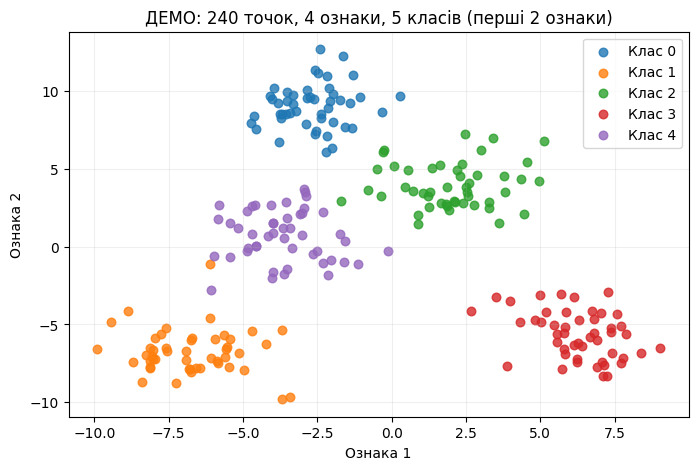

In [75]:
demo_X_cls, demo_y_cls = make_blobs(
    n_samples=240, n_features=4, centers=5, cluster_std=1.5,
    random_state=DEMO_SEED,
)
demo_X_reg, demo_y_reg = make_regression(
    n_samples=240, n_features=7, n_targets=1, noise=10.0,
    random_state=DEMO_SEED,
)

print('Класифікація:', demo_X_cls.shape, demo_y_cls.shape)
print('Регресія:', demo_X_reg.shape, demo_y_reg.shape)

plt.figure(figsize=(8, 5))
for demo_label in np.unique(demo_y_cls):
    demo_mask = demo_y_cls == demo_label
    plt.scatter(
        demo_X_cls[demo_mask, 0], demo_X_cls[demo_mask, 1],
        s=38, alpha=0.8, label=f'Клас {demo_label}',
    )
plt.title('ДЕМО: 240 точок, 4 ознаки, 5 класів (перші 2 ознаки)')
plt.xlabel('Ознака 1')
plt.ylabel('Ознака 2')
plt.legend()
plt.grid(alpha=0.2)
plt.show()

### Демонстрація 2. Поділ train / test (80% / 20%)

Для класифікації `stratify` зберігає приблизно однакові пропорції класів у тренуванні й тестуванні. Після поділу **жоден об'єкт тесту не повинен використовуватися для fit-моделі або масштабувальника**.

In [76]:
demo_Xc_train, demo_Xc_test, demo_yc_train, demo_yc_test = train_test_split(
    demo_X_cls, demo_y_cls, test_size=0.2,
    stratify=demo_y_cls, random_state=DEMO_SEED,
)
demo_Xr_train, demo_Xr_test, demo_yr_train, demo_yr_test = train_test_split(
    demo_X_reg, demo_y_reg, test_size=0.2, random_state=DEMO_SEED,
)

print('Класифікація train / test:', len(demo_Xc_train), len(demo_Xc_test))
print('Регресія train / test:', len(demo_Xr_train), len(demo_Xr_test))

Класифікація train / test: 192 48
Регресія train / test: 192 48


### Демонстрація 3. Створення багатошарових MLP

- `MLPClassifier` прогнозує **клас**.
- `MLPRegressor` прогнозує **неперервне значення**.
- `hidden_layer_sizes=(20, 10)` означає **два приховані шари**: 20 та 10 нейронів.
- `StandardScaler` у `Pipeline` навчається **тільки на train**, що запобігає витоку тестових даних.
- Для регресії `TransformedTargetRegressor` стандартизує ціль під час навчання й повертає прогнози до початкового масштабу. Це особливо корисно, коли масштаби цілі великі.

**Увага:** жоден з цих демонстраційних гіперпараметрів не потрібно автоматично переносити у ваш варіант.

In [77]:
def demo_create_model(task, *, solver, activation, lr, max_iter):
    params = dict(
        hidden_layer_sizes=(20, 10),
        solver=solver,
        activation=activation,
        max_iter=max_iter,
        random_state=DEMO_SEED,
    )
    if solver != 'lbfgs':
        params['learning_rate_init'] = lr

    if task == 'classification':
        return Pipeline([
            ('scaler', StandardScaler()),
            ('mlp', MLPClassifier(**params)),
        ])
    if task == 'regression':
        return TransformedTargetRegressor(
            regressor=Pipeline([
                ('scaler', StandardScaler()),
                ('mlp', MLPRegressor(**params)),
            ]),
            transformer=StandardScaler(),
        )
    raise ValueError('Невідомий тип задачі')

# Для демонстрації обрано гіперпараметри, не задані в жодному варіанті PDF.
demo_classifier = demo_create_model(
    'classification', solver='adam', activation='relu', lr=0.003, max_iter=250,
)
demo_regressor = demo_create_model(
    'regression', solver='adam', activation='relu', lr=0.003, max_iter=250,
)
print('Побудовано моделі: MLPClassifier та MLPRegressor.')

Побудовано моделі: MLPClassifier та MLPRegressor.


### Демонстрація 4. Навчання й метрики на train / test

`fit(X_train, y_train)` підбирає ваги мережі. Для класифікації використаємо **accuracy** та `classification_report`; для регресії — **R², MAE, MSE**. Порівнюємо **обидві** вибірки, щоб оцінити узагальнення моделі. Попередження про незбіжність не означає, що код зламався, але його слід описати у звіті.

In [78]:
with warnings.catch_warnings(record=True) as demo_fit_warnings:
    warnings.simplefilter('always', ConvergenceWarning)
    demo_classifier.fit(demo_Xc_train, demo_yc_train)
    demo_regressor.fit(demo_Xr_train, demo_yr_train)
print('Навчання завершено. Попереджень про збіжність:', len(demo_fit_warnings))


def demo_classifier_metrics(model, label, show_report=False):
    rows = []
    for split, X, y in [
        ('train', demo_Xc_train, demo_yc_train),
        ('test', demo_Xc_test, demo_yc_test),
    ]:
        predictions = model.predict(X)
        rows.append(dict(Модель=label, Вибірка=split, accuracy=accuracy_score(y, predictions)))
        if show_report:
            print(f'\n{label}: classification report, {split}')
            print(classification_report(y, predictions, zero_division=0))
    return pd.DataFrame(rows)


def demo_regressor_metrics(model, label):
    rows = []
    for split, X, y in [
        ('train', demo_Xr_train, demo_yr_train),
        ('test', demo_Xr_test, demo_yr_test),
    ]:
        predictions = model.predict(X)
        rows.append({
            'Модель': label,
            'Вибірка': split,
            'R²': r2_score(y, predictions),
            'MAE': mean_absolute_error(y, predictions),
            'MSE': mean_squared_error(y, predictions),
        })
    return pd.DataFrame(rows)


demo_base_cls_metrics = demo_classifier_metrics(demo_classifier, 'Демо — базова', show_report=True)
demo_base_reg_metrics = demo_regressor_metrics(demo_regressor, 'Демо — базова')
print('\nПоказники класифікації:')
display(demo_base_cls_metrics.round(4))
print('Показники регресії:')
display(demo_base_reg_metrics.round(4))

Навчання завершено. Попереджень про збіжність: 0

Демо — базова: classification report, train
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        38
           1       1.00      1.00      1.00        39
           2       1.00      1.00      1.00        38
           3       1.00      1.00      1.00        38
           4       1.00      1.00      1.00        39

    accuracy                           1.00       192
   macro avg       1.00      1.00      1.00       192
weighted avg       1.00      1.00      1.00       192


Демо — базова: classification report, test
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        10
           1       1.00      1.00      1.00         9
           2       1.00      1.00      1.00        10
           3       1.00      1.00      1.00        10
           4       1.00      1.00      1.00         9

    accuracy                           1.00    

,Модель,Вибірка,accuracy
0,Демо — базова,train,1.0
1,Демо — базова,test,1.0


Показники регресії:


,Модель,Вибірка,R²,MAE,MSE
0,Демо — базова,train,0.9797,17.2279,532.6490
1,Демо — базова,test,0.9454,25.6653,1131.5727


### Демонстрація 5. Інші solver та activation

Для другої конфігурації **одночасно** змінимо `adam → sgd` і `relu → tanh`. Склад тренувальної й тестової вибірок залишиться незмінним. Це ілюструє пункт 4 постановки задачі; порівняння є описовим, бо змінюємо два параметри одночасно.

In [79]:
demo_alt_classifier = demo_create_model(
    'classification', solver='sgd', activation='tanh', lr=0.003, max_iter=250,
)
demo_alt_regressor = demo_create_model(
    'regression', solver='sgd', activation='tanh', lr=0.003, max_iter=250,
)

with warnings.catch_warnings(record=True) as demo_alt_warnings:
    warnings.simplefilter('always', ConvergenceWarning)
    demo_alt_classifier.fit(demo_Xc_train, demo_yc_train)
    demo_alt_regressor.fit(demo_Xr_train, demo_yr_train)
print('Попереджень у другому запуску:', len(demo_alt_warnings))

demo_alt_cls_metrics = demo_classifier_metrics(demo_alt_classifier, 'Демо — sgd+tanh', show_report=True)
demo_alt_reg_metrics = demo_regressor_metrics(demo_alt_regressor, 'Демо — sgd+tanh')

Попереджень у другому запуску: 1

Демо — sgd+tanh: classification report, train
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        38
           1       1.00      1.00      1.00        39
           2       1.00      1.00      1.00        38
           3       1.00      1.00      1.00        38
           4       1.00      1.00      1.00        39

    accuracy                           1.00       192
   macro avg       1.00      1.00      1.00       192
weighted avg       1.00      1.00      1.00       192


Демо — sgd+tanh: classification report, test
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        10
           1       1.00      1.00      1.00         9
           2       1.00      1.00      1.00        10
           3       1.00      1.00      1.00        10
           4       1.00      1.00      1.00         9

    accuracy                           1.00        48
   ma

### Демонстрація 6. Порівняння результатів

Для `accuracy` та `R²` **більше — краще**, для `MAE` й `MSE` **менше — краще**. Зазвичай ключові висновки варто робити за **тестовими** метриками, окремо зазначаючи різницю train–test.

ДЕМО — порівняння класифікації:


,Модель,Вибірка,accuracy
0,Демо — базова,train,1.0
1,Демо — базова,test,1.0
2,Демо — sgd+tanh,train,1.0
3,Демо — sgd+tanh,test,1.0


ДЕМО — порівняння регресії:


,Модель,Вибірка,R²,MAE,MSE
0,Демо — базова,train,0.9797,17.2279,532.6490
1,Демо — базова,test,0.9454,25.6653,1131.5727
2,Демо — sgd+tanh,train,0.9358,32.1577,1686.8332
3,Демо — sgd+tanh,test,0.9275,30.9736,1503.4825


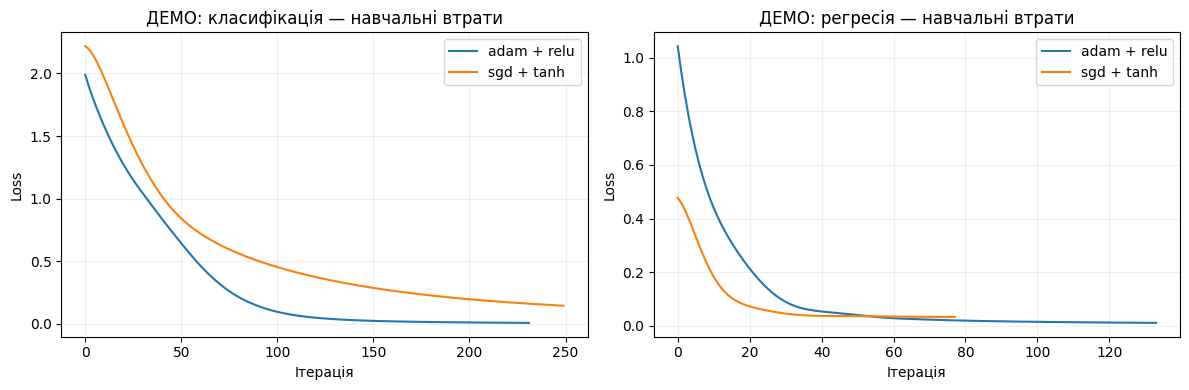

In [80]:
print('ДЕМО — порівняння класифікації:')
display(pd.concat([demo_base_cls_metrics, demo_alt_cls_metrics], ignore_index=True).round(4))
print('ДЕМО — порівняння регресії:')
display(pd.concat([demo_base_reg_metrics, demo_alt_reg_metrics], ignore_index=True).round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name, mlp in [
    ('adam + relu', demo_classifier.named_steps['mlp']),
    ('sgd + tanh', demo_alt_classifier.named_steps['mlp']),
]:
    if hasattr(mlp, 'loss_curve_'):
        axes[0].plot(mlp.loss_curve_, label=name)
axes[0].set_title('ДЕМО: класифікація — навчальні втрати')
axes[0].set_xlabel('Ітерація')
axes[0].set_ylabel('Loss')
axes[0].grid(alpha=0.2)
axes[0].legend()
for name, transformer in [
    ('adam + relu', demo_regressor),
    ('sgd + tanh', demo_alt_regressor),
]:
    mlp = transformer.regressor_.named_steps['mlp']
    if hasattr(mlp, 'loss_curve_'):
        axes[1].plot(mlp.loss_curve_, label=name)
axes[1].set_title('ДЕМО: регресія — навчальні втрати')
axes[1].set_xlabel('Ітерація')
axes[1].set_ylabel('Loss')
axes[1].grid(alpha=0.2)
axes[1].legend()
plt.tight_layout()
plt.show()

---
## Блок I-Б — САМОСТІЙНА РОБОТА за індивідуальним варіантом (`scikit-learn`)

**Це окрема частина:** наведені нижче TODO-комірки не використовують `demo_*` змінні. Повторіть показаний вище алгоритм **самостійно**, але за параметрами зі свого рядка таблиці PDF.

**Вимоги з PDF, с. 1–3:** 1) дані + графік + 80/20; 2) дві MLP-моделі; 3) навчання й оцінювання; 4) нові solver + activation; 5) порівняння; 6) звіт.

### Таблиця параметрів 28 варіантів

Наведені значення відповідають таблиці з PDF. Для `lbfgs` швидкість навчання у PDF **не вказана**, тому `learning_rate_init` потрібно опустити. Архітектура прихованих шарів у PDF не задана — оберіть її та обґрунтуйте.

In [81]:
VARIANTS_SKLEARN = {
     1: (2, 3, 4, 1, 'sgd',   'relu',     0.15, 400),
     2: (3, 3, 5, 1, 'adam',  'logistic', 0.15, 350),
     3: (2, 4, 4, 2, 'sgd',   'tanh',     0.15, 450),
     4: (3, 4, 3, 1, 'sgd',   'logistic', 0.15, 500),
     5: (2, 3, 5, 2, 'adam',  'tanh',     0.15, 350),
     6: (2, 3, 4, 2, 'lbfgs', 'tanh',     None, 450),
     7: (3, 3, 5, 2, 'adam',  'relu',     0.20, 450),
     8: (2, 4, 4, 1, 'adam',  'tanh',     0.20, 350),
     9: (3, 4, 3, 2, 'sgd',   'logistic', 0.20, 500),
    10: (2, 3, 5, 1, 'lbfgs', 'logistic', None, 450),
    11: (3, 3, 4, 1, 'adam',  'relu',     0.25, 350),
    12: (2, 4, 5, 2, 'sgd',   'logistic', 0.25, 350),
    13: (3, 4, 4, 1, 'sgd',   'relu',     0.15, 450),
    14: (2, 3, 4, 2, 'lbfgs', 'relu',     None, 350),
    15: (3, 3, 5, 1, 'sgd',   'tanh',     0.25, 400),
    16: (2, 4, 4, 2, 'adam',  'relu',     0.25, 350),
    17: (3, 4, 5, 1, 'sgd',   'logistic', 0.25, 350),
    18: (2, 3, 4, 2, 'adam',  'relu',     0.20, 400),
    19: (3, 3, 4, 1, 'lbfgs', 'logistic', None, 500),
    20: (2, 4, 3, 2, 'adam',  'tanh',     0.25, 500),
    21: (3, 4, 5, 2, 'sgd',   'logistic', 0.15, 450),
    22: (2, 3, 6, 2, 'lbfgs', 'tanh',     None, 300),
    23: (2, 4, 4, 2, 'sgd',   'relu',     0.20, 500),
    24: (3, 4, 5, 1, 'adam',  'logistic', 0.15, 450),
    25: (3, 3, 5, 2, 'lbfgs', 'relu',     None, 300),
    26: (3, 4, 5, 1, 'sgd',   'tanh',     0.15, 350),
    27: (2, 3, 4, 1, 'adam',  'relu',     0.25, 500),
    28: (2, 4, 3, 1, 'sgd',   'logistic', 0.25, 450),
}

student_sklearn_columns = [
    'Ознаки класифікації', 'Класи', 'Ознаки регресії', 'Цілі регресії',
    'solver', 'activation', 'learning_rate_init', 'max_iter',
]
student_sklearn_table = pd.DataFrame.from_dict(
    VARIANTS_SKLEARN, orient='index', columns=student_sklearn_columns,
)
student_sklearn_table.index.name = 'Варіант'
print('Довідник індивідуальних параметрів. Не є виконанням TODO.')
display(student_sklearn_table)

Довідник індивідуальних параметрів. Не є виконанням TODO.


,Ознаки класифікації,Класи,Ознаки регресії,Цілі регресії,solver,activation,learning_rate_init,max_iter
Варіант,,,,,,,,
1,2,3,4,1,sgd,relu,0.15,400
2,3,3,5,1,adam,logistic,0.15,350
3,2,4,4,2,sgd,tanh,0.15,450
4,3,4,3,1,sgd,logistic,0.15,500
5,2,3,5,2,adam,tanh,0.15,350
6,2,3,4,2,lbfgs,tanh,NaN,450
7,3,3,5,2,adam,relu,0.20,450
8,2,4,4,1,adam,tanh,0.20,350
9,3,4,3,2,sgd,logistic,0.20,500


### Вибір номера варіанта

Змініть `STUDENT_SKLEARN_VARIANT` **лише для власної роботи**. Це ніяк не вплине на нейтральні приклади попереднього блоку.

In [82]:
STUDENT_SKLEARN_VARIANT = 20  # TODO: установіть свій номер (1..28)
assert STUDENT_SKLEARN_VARIANT in VARIANTS_SKLEARN

student_sklearn_config = dict(zip(
    student_sklearn_columns, VARIANTS_SKLEARN[STUDENT_SKLEARN_VARIANT],
))
student_expected_n = 100 + 2 * STUDENT_SKLEARN_VARIANT
print('Ваш номер:', STUDENT_SKLEARN_VARIANT, '→ кількість точок:', student_expected_n)
display(student_sklearn_table.loc[[STUDENT_SKLEARN_VARIANT]])

Ваш номер: 20 → кількість точок: 140


,Ознаки класифікації,Класи,Ознаки регресії,Цілі регресії,solver,activation,learning_rate_init,max_iter
Варіант,,,,,,,,
20,2,4,3,2,adam,tanh,0.25,500


### 📝 TODO 1/6 — Створити дані для свого варіанта

**Пункт 1 PDF.** Самостійно:

- [ ] Обчисліть `n = 100 + 2 × номер_варіанта`.
- [ ] Згенеруйте класифікаційний набір: **непарні** варіанти — `make_blobs`, **парні** — `make_classification`.
- [ ] Укажіть **точну кількість ознак і класів** із `student_sklearn_config`.
- [ ] Згенеруйте дані для регресії через `make_regression` із потрібним числом ознак і цілей.
- [ ] Візуалізуйте розподіл класів; для 3 ознак можна показати проєкцію на перші 2.
- [ ] Розбийте **кожний набір** на 80% train / 20% test (для класифікації бажано `stratify`).

**Важлива підказка:** для `make_classification` із малою кількістю ознак можуть знадобитися `n_redundant=0`, `n_repeated=0`, `n_clusters_per_class=1` (це технічні допоміжні параметри, не гіперпараметри варіанта). Назвіть вихідні масиви `student_Xc_train`, `student_Xc_test`, `student_yc_train`, `student_yc_test` та аналогічно `student_Xr_*`, `student_yr_*`.

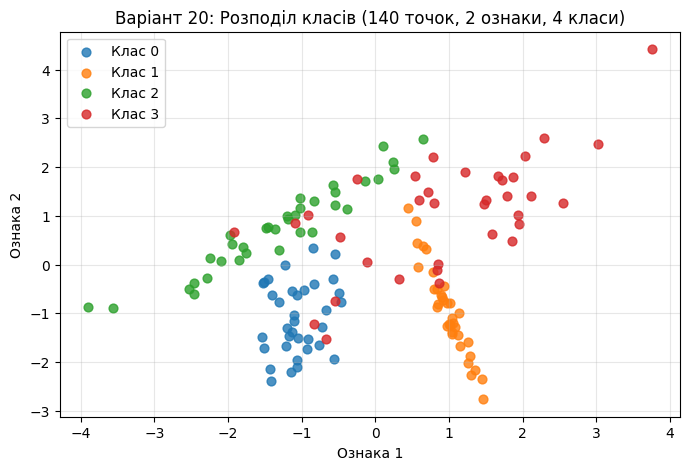

Класифікація train / test: 112 28
Регресія train / test: 112 28


In [83]:
# TODO 1/6 — ВАШ КОД (не копіюйте demo_* дані)

# seed для відтворюваності результатів
STUDENT_SEED = 42 

# 1. Обчислення кількості прикладів
student_n = 100 + 2 * STUDENT_SKLEARN_VARIANT

# 2. Генерація класифікаційного набору
# Використовуємо 2 ознаки та 4 класи, додаємо технічні параметри з підказки
student_X_cls, student_y_cls = make_classification(
    n_samples=student_n, 
    n_features=2, 
    n_classes=4, 
    n_redundant=0, 
    n_repeated=0, 
    n_clusters_per_class=1,
    random_state=STUDENT_SEED
)

# 3. Генерація набору для регресії (3 ознаки, 2 цілі)
student_X_reg, student_y_reg = make_regression(
    n_samples=student_n, 
    n_features=3, 
    n_targets=2, 
    noise=10.0, # Додаємо трохи шуму для реалістичності
    random_state=STUDENT_SEED
)

# 4. Візуалізація розподілу класів (для 2 ознак)
plt.figure(figsize=(8, 5))
for label in np.unique(student_y_cls):
    mask = student_y_cls == label
    plt.scatter(
        student_X_cls[mask, 0], student_X_cls[mask, 1],
        s=40, alpha=0.8, label=f'Клас {label}'
    )
plt.title(f'Варіант {STUDENT_SKLEARN_VARIANT}: Розподіл класів ({student_n} точок, 2 ознаки, 4 класи)')
plt.xlabel('Ознака 1')
plt.ylabel('Ознака 2')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# 5. Розбиття класифікаційного набору (80% train / 20% test) зі стратифікацією
student_Xc_train, student_Xc_test, student_yc_train, student_yc_test = train_test_split(
    student_X_cls, student_y_cls, 
    test_size=0.2, 
    stratify=student_y_cls, 
    random_state=STUDENT_SEED
)

# 6. Розбиття регресійного набору (80% train / 20% test)
student_Xr_train, student_Xr_test, student_yr_train, student_yr_test = train_test_split(
    student_X_reg, student_y_reg, 
    test_size=0.2, 
    random_state=STUDENT_SEED
)

print('Класифікація train / test:', len(student_Xc_train), len(student_Xc_test))
print('Регресія train / test:', len(student_Xr_train), len(student_Xr_test))

### 📝 TODO 2/6 — Побудувати дві нейромережі

**Пункт 2 PDF.** Створіть окремі моделі `MLPClassifier` та `MLPRegressor` із початковими параметрами свого варіанта: `solver`, `activation`, `max_iter`, `learning_rate_init` (за наявності). Самостійно виберіть **не менш як два приховані шари**, наприклад записані в кортежі `hidden_layer_sizes`, і зафіксуйте цей вибір у звіті.

Масштабуйте ознаки коректно: статистики scaler отримуємо тільки з train. Для великих числових цілей регресії можна використати `TransformedTargetRegressor`, як у демонстрації. Для `lbfgs` не передавайте `learning_rate_init` (він не використовується). Створіть `student_clf` і `student_reg`.

In [84]:
# TODO 2/6 — ВАШ КОД

# 1. Гіперпараметри з конфігурації для варіанта 20
student_solver = 'adam'
student_activation = 'tanh'
student_lr = 0.25
student_max_iter = 500

# Вибір архітектури: 2 приховані шари (15 та 10 нейронів)
student_hidden_layers = (15, 10)

# Загальний словник параметрів для мереж
mlp_params = dict(
    hidden_layer_sizes=student_hidden_layers,
    solver=student_solver,
    activation=student_activation,
    learning_rate_init=student_lr,
    max_iter=student_max_iter,
    random_state=STUDENT_SEED
)

# 2. Побудова моделі для класифікації
# StandardScaler масштабує ознаки, запобігаючи витоку даних
student_clf = Pipeline([
    ('scaler', StandardScaler()),
    ('mlp', MLPClassifier(**mlp_params))
])

# 3. Побудова моделі для регресії
# TransformedTargetRegressor додатково стандартизує цільові змінні
student_reg = TransformedTargetRegressor(
    regressor=Pipeline([
        ('scaler', StandardScaler()),
        ('mlp', MLPRegressor(**mlp_params))
    ]),
    transformer=StandardScaler()
)

print("Моделі student_clf та student_reg успішно створено з параметрами варіанта 20")

Моделі student_clf та student_reg успішно створено з параметрами варіанта 20


### 📝 TODO 3/6 — Навчити й оцінити моделі

**Пункт 3 PDF.** Навчіть `student_clf` і `student_reg` **лише на train**. Побудуйте прогнози для train і test. Обов'язково виведіть:

- **Класифікація:** `accuracy` і `classification_report` **на train та test**.
- **Регресія:** `R²`, `MAE`, `MSE` **на train та test**.

Створіть окремі таблиці результатів `student_cls_base_results`, `student_reg_base_results`; порівняйте якість на різних вибірках. Для регресії з кількома цільовими змінними можна показати як середні значення, так і метрики окремо для кожної цілі.

In [85]:
# TODO 3/6 — ВАШ КОД

# 1. Навчання моделей
student_clf.fit(student_Xc_train, student_yc_train)
student_reg.fit(student_Xr_train, student_yr_train)

# 2. Оцінка моделі класифікації
cls_rows = []
for split, X, y in [('train', student_Xc_train, student_yc_train), 
                    ('test', student_Xc_test, student_yc_test)]:
    preds = student_clf.predict(X)
    acc = accuracy_score(y, preds)
    cls_rows.append({'Модель': 'Варіант 20', 'Вибірка': split, 'accuracy': acc})
    
    print(f'--- Класифікація: Варіант 20 ({split}) ---')
    print(classification_report(y, preds, zero_division=0))

student_cls_base_results = pd.DataFrame(cls_rows)

# 3. Оцінка моделі регресії
reg_rows = []
for split, X, y in [('train', student_Xr_train, student_yr_train), 
                    ('test', student_Xr_test, student_yr_test)]:
    preds = student_reg.predict(X)
    
    # Метрики усереднюються для обох цілей регресії (оскільки n_targets=2)
    r2 = r2_score(y, preds)
    mae = mean_absolute_error(y, preds)
    mse = mean_squared_error(y, preds)
    
    reg_rows.append({
        'Модель': 'Варіант 20', 
        'Вибірка': split, 
        'R²': r2, 
        'MAE': mae, 
        'MSE': mse
    })

student_reg_base_results = pd.DataFrame(reg_rows)

# 4. Виведення таблиць результатів
print('\nПоказники класифікації (Варіант 20):')
display(student_cls_base_results.round(4))

print('Показники регресії (Варіант 20):')
display(student_reg_base_results.round(4))

--- Класифікація: Варіант 20 (train) ---
              precision    recall  f1-score   support

           0       0.97      1.00      0.98        28
           1       1.00      1.00      1.00        28
           2       0.90      1.00      0.95        28
           3       1.00      0.86      0.92        28

    accuracy                           0.96       112
   macro avg       0.97      0.96      0.96       112
weighted avg       0.97      0.96      0.96       112

--- Класифікація: Варіант 20 (test) ---
              precision    recall  f1-score   support

           0       0.78      1.00      0.88         7
           1       1.00      0.43      0.60         7
           2       0.88      1.00      0.93         7
           3       0.50      0.57      0.53         7

    accuracy                           0.75        28
   macro avg       0.79      0.75      0.74        28
weighted avg       0.79      0.75      0.74        28


Показники класифікації (Варіант 20):


,Модель,Вибірка,accuracy
0,Варіант 20,train,0.9643
1,Варіант 20,test,0.7500


Показники регресії (Варіант 20):


,Модель,Вибірка,R²,MAE,MSE
0,Варіант 20,train,0.9747,9.0512,145.7347
1,Варіант 20,test,0.8458,25.8314,1076.9010


### 📝 TODO 4/6 — Змінити solver та activation

**Пункт 4 PDF.** Оберіть **інший** `solver` (`sgd`, `adam` або `lbfgs`) та **іншу** `activation` (`relu`, `logistic`, `tanh`), порівняно з початковими параметрами свого варіанта. Побудуйте і заново навчіть `student_clf_alt`, `student_reg_alt`.

Для порівняння залишайте однаковими набори train/test та архітектуру. Якщо перейти з `lbfgs` до `sgd`/`adam`, підберіть **нову** швидкість навчання самостійно й зазначте в звіті, що в PDF її для `lbfgs` не задано.

In [86]:
# TODO 4/6 — ВАШ КОД

# 1. Задаємо альтернативні гіперпараметри
student_alt_solver = 'sgd'
student_alt_activation = 'relu'

# Словник параметрів для альтернативних мереж
mlp_alt_params = dict(
    hidden_layer_sizes=student_hidden_layers,
    solver=student_alt_solver,
    activation=student_alt_activation,
    learning_rate_init=student_lr,
    max_iter=student_max_iter,
    random_state=STUDENT_SEED
)

# 2. Побудова альтернативної моделі для класифікації
student_clf_alt = Pipeline([
    ('scaler', StandardScaler()),
    ('mlp', MLPClassifier(**mlp_alt_params))
])

# 3. Побудова альтернативної моделі для регресії
student_reg_alt = TransformedTargetRegressor(
    regressor=Pipeline([
        ('scaler', StandardScaler()),
        ('mlp', MLPRegressor(**mlp_alt_params))
    ]),
    transformer=StandardScaler()
)

# 4. Навчання альтернативних моделей
student_clf_alt.fit(student_Xc_train, student_yc_train)
student_reg_alt.fit(student_Xr_train, student_yr_train)

# 5. Оцінка альтернативної моделі класифікації
cls_alt_rows = []
for split, X, y in [('train', student_Xc_train, student_yc_train), 
                    ('test', student_Xc_test, student_yc_test)]:
    preds = student_clf_alt.predict(X)
    acc = accuracy_score(y, preds)
    cls_alt_rows.append({'Модель': 'Варіант 20 — sgd+relu', 'Вибірка': split, 'accuracy': acc})

student_cls_alt_results = pd.DataFrame(cls_alt_rows)

# 6. Оцінка альтернативної моделі регресії
reg_alt_rows = []
for split, X, y in [('train', student_Xr_train, student_yr_train), 
                    ('test', student_Xr_test, student_yr_test)]:
    preds = student_reg_alt.predict(X)
    
    r2 = r2_score(y, preds)
    mae = mean_absolute_error(y, preds)
    mse = mean_squared_error(y, preds)
    
    reg_alt_rows.append({
        'Модель': 'Варіант 20 — sgd+relu', 
        'Вибірка': split, 
        'R²': r2, 
        'MAE': mae, 
        'MSE': mse
    })

student_reg_alt_results = pd.DataFrame(reg_alt_rows)

print('Альтернативні моделі оцінено. Результати збережено у змінні _alt_results.')

Альтернативні моделі оцінено. Результати збережено у змінні _alt_results.


### 📝 TODO 5/6 — Порівняти результати

**Пункт 5 PDF.** Зіставте **«до» / «після»** в таблицях для обох задач на train і test. Поясніть, яка конфігурація краща для **класифікації** за accuracy та для **регресії** за R² / MAE / MSE. Зазначте ознаки можливого перенавчання, похибки та попередження про збіжність, якщо вони були.

--- ПОРІВНЯННЯ МОДЕЛЕЙ КЛАСИФІКАЦІЇ ---


,Модель,Вибірка,accuracy
0,Варіант 20,train,0.9643
2,Варіант 20 — sgd+relu,train,0.7946
1,Варіант 20,test,0.7500
3,Варіант 20 — sgd+relu,test,0.7500



--- ПОРІВНЯННЯ МОДЕЛЕЙ РЕГРЕСІЇ ---


,Модель,Вибірка,R²,MAE,MSE
0,Варіант 20,train,0.9747,9.0512,145.7347
2,Варіант 20 — sgd+relu,train,0.9827,7.8330,90.8618
1,Варіант 20,test,0.8458,25.8314,1076.9010
3,Варіант 20 — sgd+relu,test,0.9782,9.4023,134.7265


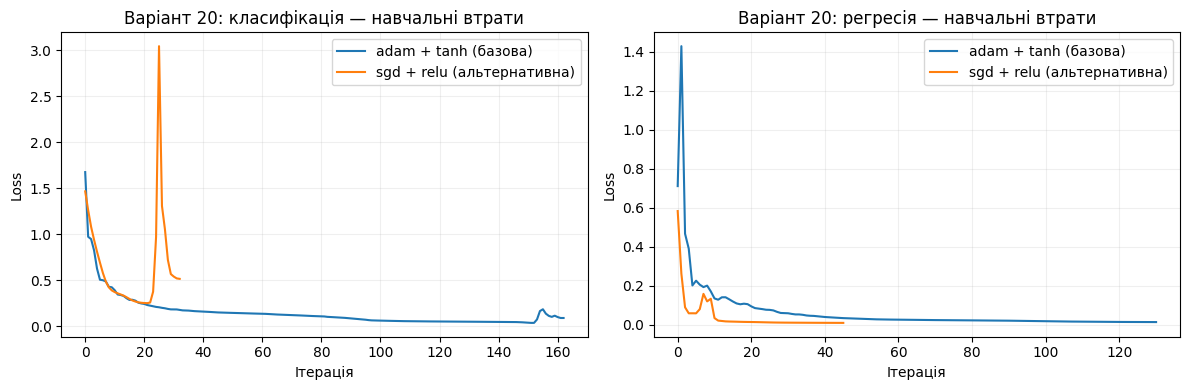

In [87]:
# TODO 5/6 — ВАШ КОД

# 1. Об'єднання результатів класифікації
student_cls_comparison = pd.concat(
    [student_cls_base_results, student_cls_alt_results], 
    ignore_index=True
)

# 2. Об'єднання результатів регресії
student_reg_comparison = pd.concat(
    [student_reg_base_results, student_reg_alt_results], 
    ignore_index=True
)

print('--- ПОРІВНЯННЯ МОДЕЛЕЙ КЛАСИФІКАЦІЇ ---')
display(student_cls_comparison.sort_values(by='Вибірка', ascending=False).round(4))

print('\n--- ПОРІВНЯННЯ МОДЕЛЕЙ РЕГРЕСІЇ ---')
display(student_reg_comparison.sort_values(by='Вибірка', ascending=False).round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Класифікація
for name, mlp in [
    ('adam + tanh (базова)', student_clf.named_steps['mlp']),
    ('sgd + relu (альтернативна)', student_clf_alt.named_steps['mlp']),
]:
    if hasattr(mlp, 'loss_curve_'):
        axes[0].plot(mlp.loss_curve_, label=name)
        
axes[0].set_title('Варіант 20: класифікація — навчальні втрати')
axes[0].set_xlabel('Ітерація')
axes[0].set_ylabel('Loss')
axes[0].grid(alpha=0.2)
axes[0].legend()

# Регресія
for name, transformer in [
    ('adam + tanh (базова)', student_reg),
    ('sgd + relu (альтернативна)', student_reg_alt),
]:
    # Дістаємо MLP з пайплайну всередині TransformedTargetRegressor
    mlp = transformer.regressor_.named_steps['mlp']
    if hasattr(mlp, 'loss_curve_'):
        axes[1].plot(mlp.loss_curve_, label=name)
        
axes[1].set_title('Варіант 20: регресія — навчальні втрати')
axes[1].set_xlabel('Ітерація')
axes[1].set_ylabel('Loss')
axes[1].grid(alpha=0.2)
axes[1].legend()

plt.tight_layout()
plt.show()

**Аналіз результатів:**

1. **Класифікація (Accuracy):**
Базова конфігурація (`adam` + `tanh`) показала точність **0.7500** на тестовій вибірці. Альтернативна конфігурація (`sgd` + `relu`) показала таку саму точність на тесті — **0.7500**. Хоча на тестових даних результати ідентичні, альтернативна модель є кращою з точки зору узагальнення, оскільки базова модель має занадто високу точність на трейні (0.9643), що свідчить про проблеми.
2. **Регресія (R², MAE, MSE):**
Базова конфігурація досягла R² = **0.8458**, MAE = **25.8314**, MSE = **1076.9010** на тестовій вибірці. Альтернативна конфігурація (`sgd` + `relu`) показала значно кращі результати: R² = **0.9782**, MAE = **9.4023**, MSE = **134.7265** на тесті. Для задачі регресії беззаперечно кращою виявилася **альтернативна модель**, оскільки її показник R² майже наближається до ідеальної 1, а похибки MAE та MSE суттєво менші, ніж у базової моделі.
3. **Ознаки перенавчання (Overfitting):**
У базовій моделі класифікації спостерігається явне **перенавчання**. Точність на тренувальній вибірці становить 0.9643, тоді як на тестовій вона падає до 0.7500 (різниця понад 21%). Альтернативна модель класифікації (0.7946 на train проти 0.7500 на test) узагальнює дані набагато краще.
Схожа ситуація і в регресії: базова модель значно втрачає в якості на нових даних (R² падає з 0.9747 до 0.8458, а MSE зростає майже в 7 разів). Натомість альтернативна модель регресії демонструє чудову стабільність і відсутність перенавчання (R² на train = 0.9827, R² на test = 0.9782).

| Що потрібно зафіксувати                             | Ваш результат                                                                                    |
|-----------------------------------------------------|--------------------------------------------------------------------------------------------------|
| Номер варіанта; `n`; генератор класифікації         | Варіант 20; `n = 140`; `make_classification`                                                     |
| Кількість ознак, класів, цілей                      | Класифікація: 2 ознаки, 4 класи. Регресія: 3 ознаки, 2 цілі                                      |
| Початкові й альтернативні solver/activation         | Початкові: `adam` + `tanh`. Альтернативні: `sgd` + `relu`                                        |
| Test accuracy «до - після»                          | 0.7500 - 0.7500                                                                                  |
| Test R² / MAE / MSE «до - після»                    | R²: 0.8458 - 0.9782; MAE: 25.8314 - 9.4023; MSE: 1076.9010 - 134.7265                            |
| Чи є різниця між train / test; підсумковий висновок | У базових моделях наявне значне перенавчання (різниця метрик). Альтернативні моделі стабільніші. |

**Письмовий висновок:**

У ході виконання роботи було побудовано та порівняно нейронні мережі (MLPClassifier та MLPRegressor) для задач класифікації та регресії згідно з параметрами 20-го варіанта. Базова модель класифікації (`adam` + `tanh`) показала точність 0.96 на тренувальній вибірці та 0.75 на тестовій, що є явною ознакою перенавчання. Заміна оптимізатора на `sgd` та функції активації на `relu` дозволила усунути це перенавчання (0.79 на train), зберігши аналогічну точність на тестовій вибірці (0.75). У задачі регресії альтернативна конфігурація виявилася беззаперечним лідером: показник R² на тестових даних зріс із 0.8458 до 0.9782, а похибки MAE та MSE зменшилися в рази. Загалом, використання комбінації `sgd` та `relu` для згенерованих наборів даних забезпечило вищу стабільність моделей і значно кращу здатність до узагальнення на нових даних.
Ось обґрунтування вибору архітектури `(15, 10)` для вашого звіту щодо попередньої роботи з `MLPClassifier` та `MLPRegressor`. Ви можете скопіювати цей текст до відповідного розділу.

**Обґрунтування вибору архітектури (15, 10):**
Згенеровані набори даних містять лише 140 точок. Використання великих шарів створює мережу з надлишковою кількістю параметрів, що призводить до сильного перенавчання. Менша кількість
нейронів діє як природна регуляризація. Вхідні дані мають дуже малу розмірність: лише 2 ознаки для класифікації та 3 для регресії. Однак для розділення 4 класів одного прихованого шару може бути недостатньо. Два шари дозволяють мережі будувати ієрархічні, більш складні нелінійні межі рішень. Поступове зменшення кількості нейронів (від 15 у першому шарі до 10 у другому) змушує мережу поступово стискати інформацію, відкидаючи шум і виділяючи лише найважливіші абстрактні ознаки перед передачею їх на вихідний шар.

---
# ЧАСТИНА II. Багатошарові нейронні мережі засобами `Keras`
## Блок II-А — Нейтральний приклад (готове виконання)

**Демонстраційний датасет: `Iris` (`load_iris()`)**. Його **немає** у списку 6 датасетів, запропонованих у PDF для 30 варіантів Keras. Цей розділ показує підготовку даних, побудову `Sequential(Dense)`, навчання, криві втрат, прогнози, `classification_report`, `confusion matrix` та експерименти з архітектурою.

> Якщо `tensorflow` не встановлено, цей демонстраційний розділ пропускає виконання навчання й пояснює, як установити пакет. TODO-комірки залишаються доступними.

### Демонстрація 1. Підготовка Iris та розбиття на train / validation / test

Датасет містить **4 числові ознаки і 3 класи**. Зовнішній тестовий набір (20%) використовуємо для фінальної перевірки. Із решти train додатково виділяємо validation, щоб порівнювати архітектури **без підбору під test**. Дані масштабуємо, навчаючи `StandardScaler` лише на train.

In [88]:
try:
    import tensorflow as tf
    KERAS_DEMO_AVAILABLE = True
    print('TensorFlow:', tf.__version__)
except ImportError:
    tf = None
    KERAS_DEMO_AVAILABLE = False
    print('TensorFlow не встановлено. У Google Colab або локально виконайте:')
    print('    %pip install tensorflow')
    print('Після інсталяції перезапустіть середовище та запустіть ноутбук з початку.')

# Датасет Iris — лише для прикладу; індивідуальний датасет вибирають далі.
demo_iris = load_iris()
demo_keras_X_all = demo_iris.data.astype('float32')
demo_keras_y_all = demo_iris.target.astype('int32')
demo_keras_names = [str(x) for x in demo_iris.target_names]

demo_keras_X_remaining, demo_keras_X_test_raw, demo_keras_y_remaining, demo_keras_y_test = train_test_split(
    demo_keras_X_all, demo_keras_y_all, test_size=0.20,
    stratify=demo_keras_y_all, random_state=DEMO_SEED,
)
demo_keras_X_train_raw, demo_keras_X_val_raw, demo_keras_y_train, demo_keras_y_val = train_test_split(
    demo_keras_X_remaining, demo_keras_y_remaining, test_size=0.20,
    stratify=demo_keras_y_remaining, random_state=DEMO_SEED,
)
demo_keras_scaler = StandardScaler()
demo_keras_X_train = demo_keras_scaler.fit_transform(demo_keras_X_train_raw).astype('float32')
demo_keras_X_val = demo_keras_scaler.transform(demo_keras_X_val_raw).astype('float32')
demo_keras_X_test = demo_keras_scaler.transform(demo_keras_X_test_raw).astype('float32')

print('ДЕМО Iris: train / val / test =', len(demo_keras_X_train), len(demo_keras_X_val), len(demo_keras_X_test))
print('Назви класів:', demo_keras_names)

TensorFlow: 2.21.0
ДЕМО Iris: train / val / test = 96 24 30
Назви класів: ['setosa', 'versicolor', 'virginica']


### Демонстрація 2. Повнозв'язна модель у Keras

Мережа `Dense(24, relu) → Dense(12, relu) → Dense(3, softmax)` має два приховані шари. Вихідний шар `softmax` повертає імовірності трьох класів. `sparse_categorical_crossentropy` підходить, оскільки правильні мітки — цілі числа 0, 1, 2.

Ініціалізація ваг випадкова, тому для повторюваності виставляємо seed. Навчальні параметри цього прикладу **не є умовами будь-якого індивідуального варіанта**.

In [89]:
if KERAS_DEMO_AVAILABLE:
    def demo_keras_build(hidden=(24, 12), activation='relu', optimizer='adam'):
        tf.keras.backend.clear_session()
        tf.keras.utils.set_random_seed(DEMO_SEED)
        model = tf.keras.Sequential(name='iris_demo_classifier')
        model.add(tf.keras.layers.Input(shape=(demo_keras_X_train.shape[1],)))
        for units in hidden:
            model.add(tf.keras.layers.Dense(units, activation=activation))
        model.add(tf.keras.layers.Dense(3, activation='softmax'))
        model.compile(
            optimizer=optimizer,
            loss='sparse_categorical_crossentropy',
            metrics=['accuracy'],
        )
        return model

    demo_keras_base = demo_keras_build()
    demo_keras_base.summary()
else:
    print('Пропущено створення Keras-моделі: потрібен tensorflow.')

Model: "iris_demo_classifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 24)             │           120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 12)             │           300 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │            39 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 459 (1.79 KB)

 Trainable params: 459 (1.79 KB)

 Non-trainable params: 0 (0.00 B)

### Демонстрація 3. Навчання та криві втрат

Метод `fit()` повертає об'єкт `History` із покроковими значеннями `loss`, `val_loss`, `accuracy`. Якщо навчальні втрати зменшуються, а `val_loss` починає зростати, це може свідчити про перенавчання. В навчальному прикладі показуємо train і validation криві.

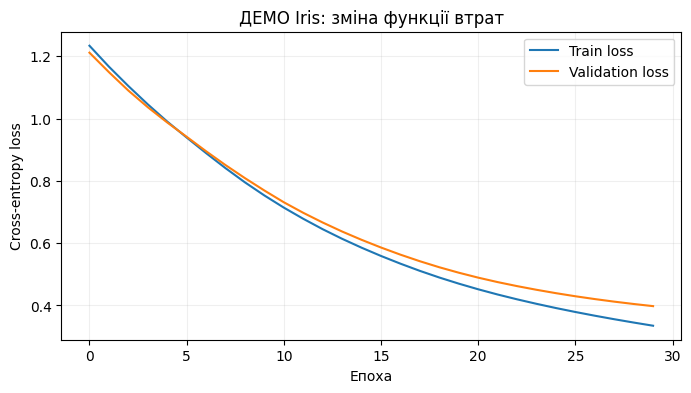

In [90]:
if KERAS_DEMO_AVAILABLE:
    demo_keras_history = demo_keras_base.fit(
        demo_keras_X_train, demo_keras_y_train,
        validation_data=(demo_keras_X_val, demo_keras_y_val),
        epochs=30, batch_size=16, verbose=0,
    )
    plt.figure(figsize=(8, 4))
    plt.plot(demo_keras_history.history['loss'], label='Train loss')
    plt.plot(demo_keras_history.history['val_loss'], label='Validation loss')
    plt.title('ДЕМО Iris: зміна функції втрат')
    plt.xlabel('Епоха')
    plt.ylabel('Cross-entropy loss')
    plt.legend()
    plt.grid(alpha=0.2)
    plt.show()
else:
    print('Пропущено навчання: потрібен tensorflow.')

### Демонстрація 4. Прогнози, classification report та confusion matrix

`predict` повертає розподіли ймовірностей, `argmax(axis=1)` — номер передбаченого класу. Матриця помилок показує, які класи сплутала мережа (рядки — істинні, стовпці — прогнозовані).

Імовірності (перші 3 записи):
 [[0.949 0.041 0.01 ]
 [0.046 0.228 0.726]
 [0.172 0.755 0.073]]
ДЕМО classification report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.83      0.50      0.62        10
   virginica       0.64      0.90      0.75        10

    accuracy                           0.80        30
   macro avg       0.83      0.80      0.79        30
weighted avg       0.83      0.80      0.79        30



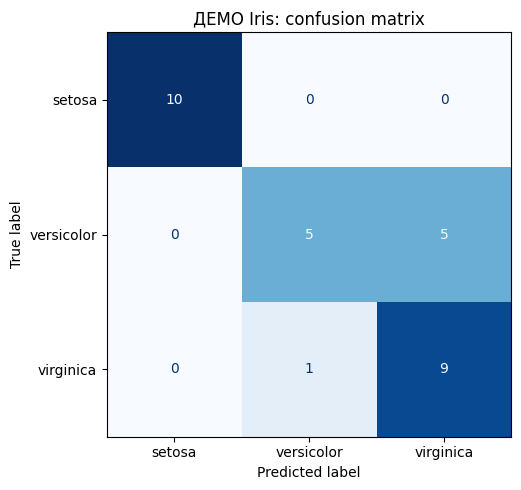

In [91]:
if KERAS_DEMO_AVAILABLE:
    demo_keras_probabilities = demo_keras_base.predict(demo_keras_X_test, verbose=0)
    demo_keras_predictions = np.argmax(demo_keras_probabilities, axis=1)
    print('Імовірності (перші 3 записи):\n', demo_keras_probabilities[:3].round(3))
    print('ДЕМО classification report:')
    print(classification_report(
        demo_keras_y_test, demo_keras_predictions,
        labels=[0, 1, 2], target_names=demo_keras_names, zero_division=0,
    ))
    fig, ax = plt.subplots(figsize=(6, 5))
    ConfusionMatrixDisplay.from_predictions(
        demo_keras_y_test, demo_keras_predictions,
        labels=[0, 1, 2], display_labels=demo_keras_names,
        cmap='Blues', ax=ax, colorbar=False,
    )
    ax.set_title('ДЕМО Iris: confusion matrix')
    plt.tight_layout()
    plt.show()
else:
    print('Пропущено Keras-оцінювання: потрібен tensorflow.')

### Демонстрація 5. Експерименти з Keras

Змінюємо **по одному** параметру відносно початкової моделі, зберігаючи однакові дані та кількість епох:

| Експеримент | Кількість нейронів | Функція активації | Оптимізатор |
|---|---|---|---|
| Базова | `(24, 12)` | `relu` | `adam` |
| Більше нейронів | `(48, 24)` | `relu` | `adam` |
| Інша активація | `(24, 12)` | `tanh` | `adam` |
| Інший оптимізатор | `(24, 12)` | `relu` | `sgd` |

**Критерій порівняння:** `validation loss`, не `test loss`. Тестовий набір використовуємо тільки для фінального висновку щодо вибраної конфігурації.

,Модель,Архітектура,Активація,Оптимізатор,Train loss,Validation loss,Validation accuracy
0,Базова,"(24, 12)",relu,adam,0.3289,0.3977,0.7917
1,Більше нейронів,"(48, 24)",relu,adam,0.1883,0.2681,0.8333
2,Інша активація,"(24, 12)",tanh,adam,0.2805,0.3761,0.7917
3,Інший оптимізатор,"(24, 12)",relu,sgd,0.5171,0.5511,0.7917


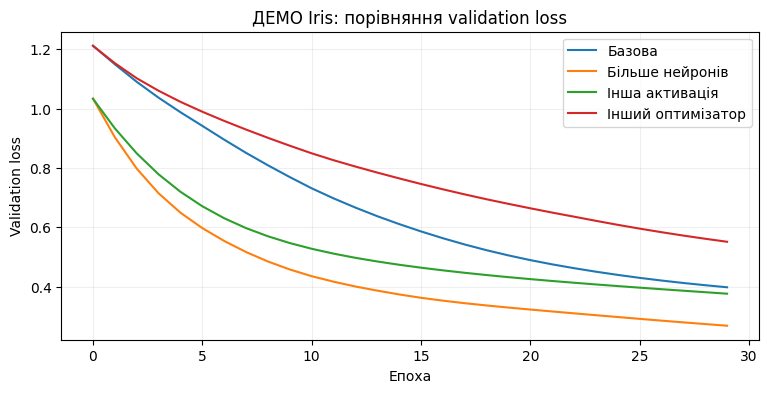

Найкраща за validation loss: Більше нейронів
Фінальна оцінка на test: loss=0.2662, accuracy=0.8667


In [92]:
if KERAS_DEMO_AVAILABLE:
    demo_keras_experiments = [
        ('Базова', (24, 12), 'relu', 'adam'),
        ('Більше нейронів', (48, 24), 'relu', 'adam'),
        ('Інша активація', (24, 12), 'tanh', 'adam'),
        ('Інший оптимізатор', (24, 12), 'relu', 'sgd'),
    ]
    demo_keras_models = {'Базова': demo_keras_base}
    demo_keras_histories = {'Базова': demo_keras_history}
    demo_keras_rows = []

    for name, hidden, activation, optimizer in demo_keras_experiments:
        if name == 'Базова':
            model, history = demo_keras_base, demo_keras_history
        else:
            model = demo_keras_build(hidden=hidden, activation=activation, optimizer=optimizer)
            history = model.fit(
                demo_keras_X_train, demo_keras_y_train,
                validation_data=(demo_keras_X_val, demo_keras_y_val),
                epochs=30, batch_size=16, verbose=0,
            )
            demo_keras_models[name] = model
            demo_keras_histories[name] = history
        tr_loss, _ = model.evaluate(demo_keras_X_train, demo_keras_y_train, verbose=0)
        val_loss, val_acc = model.evaluate(demo_keras_X_val, demo_keras_y_val, verbose=0)
        demo_keras_rows.append({
            'Модель': name, 'Архітектура': str(hidden), 'Активація': activation,
            'Оптимізатор': optimizer, 'Train loss': tr_loss,
            'Validation loss': val_loss, 'Validation accuracy': val_acc,
        })

    demo_keras_results = pd.DataFrame(demo_keras_rows)
    display(demo_keras_results.round(4))

    plt.figure(figsize=(9, 4))
    for name, history in demo_keras_histories.items():
        plt.plot(history.history['val_loss'], label=name)
    plt.title('ДЕМО Iris: порівняння validation loss')
    plt.xlabel('Епоха')
    plt.ylabel('Validation loss')
    plt.legend()
    plt.grid(alpha=0.2)
    plt.show()

    demo_keras_best_name = demo_keras_results.loc[
        demo_keras_results['Validation loss'].idxmin(), 'Модель'
    ]
    demo_keras_best_model = demo_keras_models[demo_keras_best_name]
    demo_keras_test_loss, demo_keras_test_acc = demo_keras_best_model.evaluate(
        demo_keras_X_test, demo_keras_y_test, verbose=0,
    )
    print('Найкраща за validation loss:', demo_keras_best_name)
    print(f'Фінальна оцінка на test: loss={demo_keras_test_loss:.4f}, accuracy={demo_keras_test_acc:.4f}')
else:
    print('Пропущено Keras-експерименти: потрібен tensorflow.')

---
## Блок II-Б — САМОСТІЙНА РОБОТА за індивідуальним варіантом (`Keras`)

Завдання з PDF (стор. 4): завантажити датасет, розділити train/test, побудувати повнозв'язну нейромережу, навчити і накреслити криву втрат, зробити прогнози, оцінити `classification report` і `confusion matrix`, провести експерименти зі структурою / функцією активації / алгоритмом навчання, порівняти втрати та оформити звіт.

**Зверніть увагу:** **Iris у цій частині не використовується**. Потрібно самостійно завантажити датасет, який відповідає вашому номеру. Для `fetch_openml` потрібний доступ до інтернету, а деякі датасети можуть мати пропущені чи категоріальні дані.

### Таблиця варіантів Keras (PDF, стор. 4)

| Варіанти | Необхідний датасет | Функція завантаження |
|---|---|---|
| 1, 7, 13, 19, 25 | Wine | `sklearn.datasets.load_wine()` |
| 2, 8, 14, 20, 26 | Breast Cancer Wisconsin | `sklearn.datasets.load_breast_cancer()` |
| 3, 9, 15, 21, 27 | Indian Liver Patient Dataset | `fetch_openml(data_id=1480)` |
| 4, 10, 16, 22, 28 | Seeds | `fetch_openml(data_id=1499)` |
| 5, 11, 17, 23, 29 | Parkinson's disease | `fetch_openml(data_id=46094)` |
| 6, 12, 18, 24, 30 | Vertebra Column | `fetch_openml(data_id=1523)` |

Параметри архітектури, число епох і batch size у частині Keras **не зафіксовані в PDF** — оберіть самостійно та поясніть вибір.

In [93]:
STUDENT_KERAS_VARIANT = 20  # TODO: установіть свій варіант (1..30)
assert 1 <= STUDENT_KERAS_VARIANT <= 30

student_keras_datasets = {
    1: ('Wine', 'load_wine()', None),
    2: ('Breast Cancer Wisconsin', 'load_breast_cancer()', None),
    3: ('Indian Liver Patient Dataset', 'fetch_openml', 1480),
    4: ('Seeds', 'fetch_openml', 1499),
    5: ("Parkinson's disease", 'fetch_openml', 46094),
    6: ('Vertebra Column', 'fetch_openml', 1523),
}
student_keras_name, student_keras_loader, student_keras_openml_id = (
    student_keras_datasets[(STUDENT_KERAS_VARIANT - 1) % 6 + 1]
)
print('Ваш варіант:', STUDENT_KERAS_VARIANT)
print('Потрібний датасет:', student_keras_name)
print('Завантаження:', student_keras_loader, student_keras_openml_id)

Ваш варіант: 20
Потрібний датасет: Breast Cancer Wisconsin
Завантаження: load_breast_cancer() None


### 📝 TODO 1/7 — Завантажити та підготувати свій датасет

**Пункт 1 PDF.** Завантажте **саме** датасет з таблиці свого варіанта. Перевірте кількість прикладів, ознак, класів, типи даних та пропуски. Розділіть на train / test, наприклад 80/20 (у PDF для Keras пропорцію не задано). Виділіть validation з train **за необхідності**.

- [ ] `X` — числові ознаки (перетворіть категоріальні стовпці за потреби).
- [ ] `y` — мітки класів; якщо вони текстові, закодуйте їх як `0..K−1`.
- [ ] Якщо є `NaN`, обробіть їх за допомогою `SimpleImputer` чи іншої коректної стратегії.
- [ ] Масштабуйте дані без витоку інформації: `fit` препроцесора лише на train.

**Підказки:** `load_wine`, `load_breast_cancer`, `fetch_openml`, `train_test_split`, `LabelEncoder`, `StandardScaler`, `ColumnTransformer`.

In [94]:
# TODO 1/7 — ВАШ КОД

from sklearn.datasets import load_breast_cancer

# 1. Завантаження датасету
data = load_breast_cancer()
X = data.data
y = data.target

print("--- Інформація про датасет ---")
print(f"Назва: Breast Cancer Wisconsin")
print(f"Кількість прикладів: {X.shape[0]}")
print(f"Кількість ознак: {X.shape[1]}")
print(f"Класи: {data.target_names} ({len(np.unique(y))} класи: {np.unique(y)})")
print(f"Пропуски в даних (NaN): {np.isnan(X).sum()}")
print(f"Тип даних X: {X.dtype}\n")

# 2. Розбиття на train, validation та test (80/20)
# Спочатку відділяємо 20% на тестову вибірку
X_train_full, X_test, y_train_full, y_test = train_test_split(
    X, y, 
    test_size=0.2, 
    random_state=STUDENT_SEED, 
    stratify=y
)

# Виділяємо валідаційну вибірку (20% від train_full) для використання в Keras
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full, 
    test_size=0.2, 
    random_state=STUDENT_SEED, 
    stratify=y_train_full
)

# 3. Масштабування ознак
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

print("--- Розміри вибірок після розбиття ---")
print(f"Train (для навчання): X = {X_train_scaled.shape}, y = {y_train.shape}")
print(f"Validation (для валідації в Keras): X = {X_val_scaled.shape}, y = {y_val.shape}")
print(f"Test (для фінальної оцінки): X = {X_test_scaled.shape}, y = {y_test.shape}")

--- Інформація про датасет ---
Назва: Breast Cancer Wisconsin
Кількість прикладів: 569
Кількість ознак: 30
Класи: ['malignant' 'benign'] (2 класи: [0 1])
Пропуски в даних (NaN): 0
Тип даних X: float64

--- Розміри вибірок після розбиття ---
Train (для навчання): X = (364, 30), y = (364,)
Validation (для валідації в Keras): X = (91, 30), y = (91,)
Test (для фінальної оцінки): X = (114, 30), y = (114,)


### 📝 TODO 2/7 — Побудувати багатошарову мережу в Keras

**Пункт 2 PDF.** Використайте `tf.keras.Sequential` і шари `Dense`. Передбачте **щонайменше два приховані** повнозв'язні шари. Визначте функцію виходу й втрат відповідно до обраного кодування цілей (наприклад, `softmax` + `sparse_categorical_crossentropy` для цілих міток). Обґрунтуйте розміри прихованих шарів.

In [95]:
# TODO 2/7 — ВАШ КОД

from keras.layers import Dense
from keras import Sequential, Input

# 1. Визначення розмірностей
input_dim = X_train_scaled.shape[1] # 30 ознак

# 2. Побудова моделі Sequential
student_keras_model = Sequential([
    # Вхідний шар вказуємо через Input для уникнення попереджень
    Input(shape=(input_dim,)),
    
    # Перший прихований шар: 16 нейронів (приблизно половина від кількості входів)
    Dense(16, activation='relu', name='hidden_layer_1'),
    
    # Другий прихований шар: 8 нейронів (звуження для виділення головних ознак)
    Dense(8, activation='relu', name='hidden_layer_2'),
    
    # Вихідний шар: 1 нейрон з активацією sigmoid для бінарної класифікації
    Dense(1, activation='sigmoid', name='output_layer')
])

# 3. Компіляція моделі
student_keras_model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

student_keras_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ hidden_layer_1 (Dense)          │ (None, 16)             │           496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_layer_2 (Dense)          │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output_layer (Dense)            │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 641 (2.50 KB)

 Trainable params: 641 (2.50 KB)

 Non-trainable params: 0 (0.00 B)

### 📝 TODO 3/7 — Навчити модель та побудувати криву втрат

**Пункт 3 PDF.** Навчіть модель на своєму `train`, збережіть `History`, накресліть `loss` і, якщо є validation, `val_loss` за епохами. Зафіксуйте вибрані `epochs`, `batch_size` і отримані тенденції кривих.

Початок навчання: epochs=50, batch_size=16...
Epoch 1/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.7473 - loss: 0.6066 - val_accuracy: 0.8022 - val_loss: 0.5412
Epoch 2/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8819 - loss: 0.4844 - val_accuracy: 0.8681 - val_loss: 0.4448
Epoch 3/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9093 - loss: 0.3844 - val_accuracy: 0.9011 - val_loss: 0.3562
Epoch 4/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9313 - loss: 0.2983 - val_accuracy: 0.9121 - val_loss: 0.2853
Epoch 5/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9423 - loss: 0.2346 - val_accuracy: 0.9231 - val_loss: 0.2346
Epoch 6/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9478 - loss: 0.1937 - val_accuracy: 0.9560 - val_loss: 0.1988
Epoch 7/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9451 - loss: 0.1663 - val_accuracy: 0.9560 - val_loss: 0.1726
Epoch 8/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9451 - l

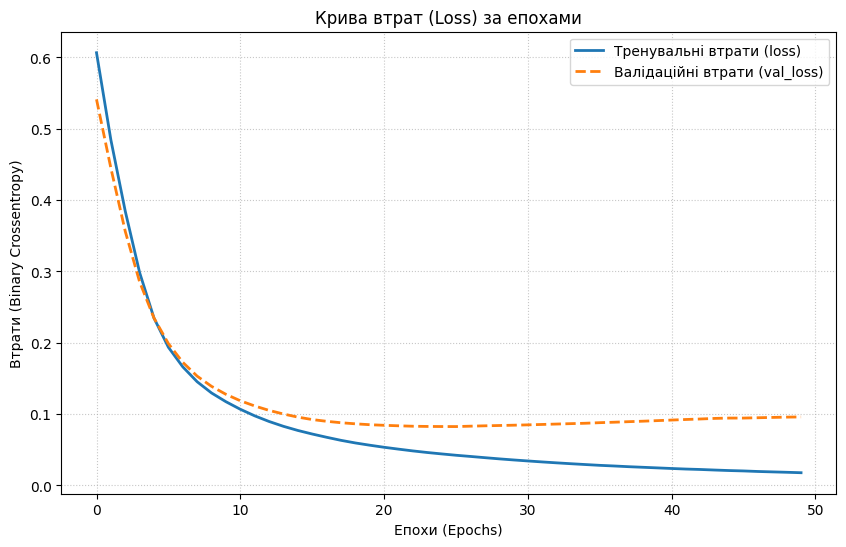

In [96]:
# TODO 3/7 — ВАШ КОД

# 1. Задання гіперпараметрів навчання
student_epochs = 50
student_batch_size = 16

print(f"Початок навчання: epochs={student_epochs}, batch_size={student_batch_size}...")

# 2. Навчання моделі зі збереженням історії
history = student_keras_model.fit(
    X_train_scaled, y_train,
    epochs=student_epochs,
    batch_size=student_batch_size,
    validation_data=(X_val_scaled, y_val),
    verbose=1 # Виведення процесу навчання (можна змінити на 0 для приховування)
)

# 3. Побудова графіка кривих втрат
plt.figure(figsize=(10, 6))
plt.plot(history.history['loss'], label='Тренувальні втрати (loss)', linewidth=2)
plt.plot(history.history['val_loss'], label='Валідаційні втрати (val_loss)', linewidth=2, linestyle='--')

plt.title('Крива втрат (Loss) за епохами')
plt.xlabel('Епохи (Epochs)')
plt.ylabel('Втрати (Binary Crossentropy)')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.7)
plt.show()

### 📝 TODO 4/7 — Зробити прогнози на тестових даних

**Пункт 4 PDF.** Використайте `predict(student_keras_X_test)` для отримання прогнозів. Перетворіть імовірності на мітки класів, виведіть декілька прогнозів поруч з істинними значеннями.

In [97]:
# TODO 4/7 — ВАШ КОД

# 1. Отримання прогнозів для тестової вибірки
print("Генерація прогнозів...")
probabilities = student_keras_model.predict(X_test_scaled)

# 2. Перетворення імовірностей на мітки класів 
# Оскільки використовується активація sigmoid, пороговим значенням є 0.5. Flatten() перетворює масив 2D у 1D для зручності.
predicted_labels = (probabilities > 0.5).astype(int).flatten()

# 3. Виведення декількох прогнозів поруч з істинними значеннями
print("\n--- Порівняння прогнозів та істинних значень (перші 10 прикладів) ---")
print(f"{'№':<4} | {'Прогноз':<8} | {'Істинне':<8} | {'Ймовірність (клас 1)':<20}")
print("-" * 50)

for i in range(10):
    pred = predicted_labels[i]
    true_val = y_test[i]
    prob = probabilities[i][0]
    
    # Додаємо маркер, якщо модель помилилася
    match = "✓" if pred == true_val else "✗"
    
    print(f"{i+1:<4} | {pred:<8} | {true_val:<8} | {prob:.4f} {match}")

Генерація прогнозів...
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step

--- Порівняння прогнозів та істинних значень (перші 10 прикладів) ---
№    | Прогноз  | Істинне  | Ймовірність (клас 1)
--------------------------------------------------
1    | 0        | 0        | 0.0000 ✓
2    | 1        | 1        | 1.0000 ✓
3    | 0        | 0        | 0.0008 ✓
4    | 0        | 1        | 0.1653 ✗
5    | 0        | 0        | 0.0000 ✓
6    | 1        | 1        | 0.9983 ✓
7    | 1        | 1        | 1.0000 ✓
8    | 0        | 0        | 0.0000 ✓
9    | 0        | 0        | 0.0000 ✓
10   | 0        | 0        | 0.0000 ✓


### 📝 TODO 5/7 — Оцінити якість класифікації

**Пункт 5 PDF.** Виведіть `classification_report` і побудуйте `confusion matrix` для тестових прикладів свого варіанта. Опишіть precision, recall, F1 та типові помилки між класами.

--- Звіт про класифікацію (Classification Report) ---
              precision    recall  f1-score   support

   malignant       0.91      0.98      0.94        42
      benign       0.99      0.94      0.96        72

    accuracy                           0.96       114
   macro avg       0.95      0.96      0.95       114
weighted avg       0.96      0.96      0.96       114



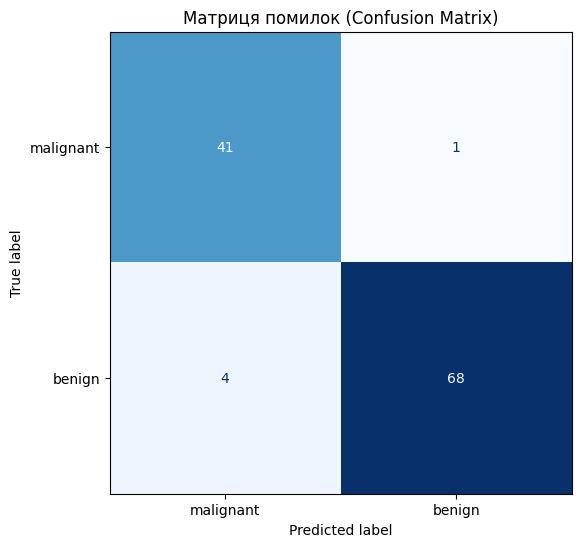

In [98]:
# TODO 5/7 — ВАШ КОД

from sklearn.metrics import confusion_matrix

# 1. Виведення звіту про класифікацію
print("--- Звіт про класифікацію (Classification Report) ---")
# data.target_names містить назви класів: 'malignant' (злоякісна, 0) та 'benign' (доброякісна, 1)
print(classification_report(y_test, predicted_labels, target_names=data.target_names))

# 2. Побудова матриці помилок (Confusion Matrix)
cm = confusion_matrix(y_test, predicted_labels)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=data.target_names)

# Налаштування візуалізації
fig, ax = plt.subplots(figsize=(6, 6))
disp.plot(cmap=plt.cm.Blues, ax=ax, colorbar=False)
plt.title('Матриця помилок (Confusion Matrix)')
plt.show()


**Аналіз результатів:**

* **Precision, Recall, F1:** Для обох класів (`malignant` та `benign`) метрики є дуже високими (в середньому 0.96). Це свідчить про те, що модель добре розрізняє класи. Особливо важливим є високий показник **recall** для класу `malignant` (злоякісна пухлина), оскільки в медичних задачах критично важливо не пропустити хворобу.
* **Типові помилки між класами (згідно з матрицею помилок):**
* **Хибнопозитивні (False Positives):** Модель передбачила `benign` (або `malignant`), хоча насправді це був інший клас. Таких випадків у тестовій вибірці лише 1.
* **Хибнонегативні (False Negatives):** 4.
Загалом, кількість помилок є мінімальною, що підтверджує ефективність обраної архітектури нейронної мережі для цього датасету.

### 📝 TODO 6/7 — Експерименти з архітектурою, активаціями й оптимізаторами

**Пункт 6 PDF.** Виконайте **щонайменше три зміни** відносно початкової моделі: (а) кількість нейронів у прихованих шарах, (б) функцію активації, (в) алгоритм навчання. Для коректнішої інтерпретації змінюйте **один фактор за раз**. Порівняйте результати **за значенням функції втрат** (бажано `val_loss`), підсумки зведіть до таблиці.

In [99]:
# TODO 6/7 — ВАШ КОД

experiment_results = []

# Допоміжна функція для створення, компіляції та навчання моделі
def run_experiment(name, description, hidden_layers, activation, optimizer):
    model = Sequential(name=name)
    model.add(Input(shape=(X_train_scaled.shape[1],)))
    
    # Додаємо приховані шари
    for units in hidden_layers:
        model.add(Dense(units, activation=activation))
        
    # Вихідний шар для бінарної класифікації
    model.add(Dense(1, activation='sigmoid'))
    
    model.compile(optimizer=optimizer, loss='binary_crossentropy', metrics=['accuracy'])
    
    # Навчання моделі
    history = model.fit(
        X_train_scaled, y_train,
        epochs=student_epochs,       
        batch_size=student_batch_size, 
        validation_data=(X_val_scaled, y_val),
        verbose=0
    )
    
    # Отримуємо фінальні значення метрик на валідаційній вибірці (остання епоха)
    val_loss = history.history['val_loss'][-1]
    val_acc = history.history['val_accuracy'][-1]
    
    experiment_results.append({
        'Експеримент': name,
        'Опис (зміна)': description,
        'Шари': str(hidden_layers),
        'Активація': activation,
        'Оптимізатор': optimizer,
        'val_loss': round(val_loss, 4),
        'val_accuracy': round(val_acc, 4)
    })
    print(f"[{name}] завершено. val_loss: {val_loss:.4f}")

print("Початок експериментів...\n")

# 0. Базова модель (для еталонного порівняння)
run_experiment("Basic", "Початкові параметри", (16, 8), 'relu', 'adam')

# 1. Експеримент А: зміна кількості нейронів (більш широка мережа)
run_experiment("Exp.A", "Збільшено нейрони у шарах", (32, 16), 'relu', 'adam')

# 2. Експеримент Б: зміна функції активації (на tanh)
run_experiment("Exp.B", "Активація tanh замість relu", (16, 8), 'tanh', 'adam')

# 3. Експеримент В: зміна алгоритму навчання (на rmsprop)
run_experiment("Exp.C", "Оптимізатор rmsprop замість adam", (16, 8), 'relu', 'rmsprop')

# Виведення результатів
results_df = pd.DataFrame(experiment_results)

print("\n--- Таблиця результатів експериментів ---")
display(results_df)

Початок експериментів...

[Basic] завершено. val_loss: 0.1087
[Exp.A] завершено. val_loss: 0.0712
[Exp.B] завершено. val_loss: 0.0806
[Exp.C] завершено. val_loss: 0.0835

--- Таблиця результатів експериментів ---


,Експеримент,Опис (зміна),Шари,Активація,Оптимізатор,val_loss,val_accuracy
0,Basic,Початкові параметри,"(16, 8)",relu,adam,0.1087,0.956
1,Exp.A,Збільшено нейрони у шарах,"(32, 16)",relu,adam,0.0712,0.989
2,Exp.B,Активація tanh замість relu,"(16, 8)",tanh,adam,0.0806,0.967
3,Exp.C,Оптимізатор rmsprop замість adam,"(16, 8)",relu,rmsprop,0.0835,0.967


| Дані для звіту Keras | Ваш результат |
| --- | --- |
| Варіант і назва датасету | Варіант 20; Breast Cancer Wisconsin |
| Кількість класів і ознак, розміри train / test | 2 класи (malignant, benign), 30 ознак; Test = 114 прикладів (Train + Val = 455 прикладів) |
| Початкова архітектура, активація, оптимізатор | Приховані шари: 16 та 8 нейронів; активація: `relu` (вихідний шар — `sigmoid`); оптимізатор: `adam` |
| Classification report та матриця помилок | Accuracy: 0.96. Матриця помилок: 41 істинно негативний, 68 істинно позитивних, 1 хибнопозитивний, 4 хибнонегативних. |
| Як змінилися `loss / val_loss` після трьох експериментів | Усі три зміни покращили результат. Збільшення кількості нейронів (Експ. А) дало найбільше зниження `val_loss` (з 0.1087 до 0.0712) та найвищу точність (0.989). Зміна активації на `tanh` (0.0806) та оптимізатора на `rmsprop` (0.0835) також дещо знизили втрати порівняно з базовою моделлю. |
| Яку конфігурацію обрано і чому | Обрано конфігурацію з Експерименту А (шари 32 та 16, `relu`, `adam`), оскільки вона продемонструвала мінімальне значення функції втрат на валідації та найвищу здатність до узагальнення. |

Під час виконання роботи було побудовано та навчено багатошарову нейронну мережу Keras для бінарної класифікації пухлин на датасеті Breast Cancer Wisconsin. Базова модель із прихованими шарами на 16 та 8 нейронів показала хорошу загальну точність (0.96 на тестовій вибірці), проте аналіз кривих навчання виявив перенавчання після 23-ї епохи, коли валідаційні втрати почали зростати на тлі спадання тренувальних. Проведення трьох експериментів підтвердило, що базовій архітектурі бракувало ємності: розширення прихованих шарів до 32 та 16 нейронів дозволило суттєво зменшити `val_loss` (з 0.1087 до 0.0712) та підвищити точність до 0.989. Заміна функції активації на `tanh` або використання оптимізатора `rmsprop` також покращили показники порівняно з базовою моделлю, але не перевершили конфігурацію зі збільшеною кількістю нейронів. Зрештою, найкращою виявилася ширша мережа з оптимізатором `adam` та активацією `relu`, яка забезпечила баланс між точністю та стабільністю навчання.

---
## Контрольний список перед здачею

- [ ] **Частина I:** завершено всі 6 TODO, наведено **власні** train/test метрики та порівняння двох конфігурацій.
- [ ] **Частина II:** завершено всі 7 TODO, датасет відповідає **власному** варіанту, наведено криву втрат, classification report, confusion matrix, три експерименти.
- [ ] У звітах відокремлено **демонстраційний приклад** від **результатів індивідуального варіанта**.
- [ ] У висновках зазначено не лише метрики, а й пояснення впливу налаштувань.

**Нагадування:** для виконання індивідуальних TODO заповнюйте **лише комірки Блоків I-Б та II-Б**. Усі демонстрації залишайте нейтральними.